# BEA C7 breakthrough and timing comparison

This notebook reads the simulations produced in `breakthrough/`; it does not create or run simulations. It pairs MPD and Langmuir directories with the same integrator, grid size, velocity, and repetition.

Run the simulations first from the `breakthrough` directory:

```bash
python3 run.py
```

The first figure overlays every paired breakthrough curve (MPD solid, Langmuir dashed). The second figure compares Ruptura's reported total runtime for every setting.

In [1]:
from __future__ import annotations

from itertools import product
from pathlib import Path
import json
import re
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np


def locate_example_directory() -> Path:
    candidates = (
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd() / 'examples' / 'MPD' / 'BEA-alkanes',
    )
    for candidate in candidates:
        if (candidate / 'breakthrough').is_dir() and (candidate / 'mpd').is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        'Run this notebook from the BEA-alkanes example directory or the Ruptura repository root.'
    )


EXAMPLE_DIR = locate_example_directory()
RUN_ROOT = EXAMPLE_DIR / 'breakthrough'
MODELS = ('MPD', 'Langmuir')
INTEGRATORS = ('CVODE', 'RungeKutta3')
GRID_POINTS = (20, 50, 100)
VELOCITIES = (0.019, 0.19)
COMPONENTS = ('nC7', 'C6m2', 'C6m3', 'C5m2m2', 'C5m2m3', 'C5m2m4', 'C5m3m3')
COMPONENT_INDEX = {name: index for index, name in enumerate(COMPONENTS, start=1)}

print(f'Results directory: {RUN_ROOT}')

Results directory: /Users/youriran/pusan/ruptura/examples/MPD/BEA-alkanes/breakthrough


## Discover completed simulations

Settings are taken from the directory names generated for the benchmark. Timing is read directly from the final `Total time` line in each `ruptura.log`, so the notebook follows the output of the parallel runner without requiring a separate timing CSV.

In [2]:
RUN_PATTERN = re.compile(
    r'^(mpd|langmuir)_(cvode|rungekutta3)_n(\d+)_v([0-9p]+)_r(\d+)$',
    flags=re.IGNORECASE,
)
TOTAL_TIME_PATTERN = re.compile(r'^Total time:\s+([0-9.eE+-]+) s$', flags=re.MULTILINE)
MODEL_NAMES = {'mpd': 'MPD', 'langmuir': 'Langmuir'}
INTEGRATOR_NAMES = {'cvode': 'CVODE', 'rungekutta3': 'RungeKutta3'}


def read_total_time(log_path: Path) -> float:
    if not log_path.is_file():
        return np.nan
    matches = TOTAL_TIME_PATTERN.findall(log_path.read_text(encoding='utf-8', errors='replace'))
    return float(matches[-1]) if matches else np.nan


def discover_runs(root: Path) -> list[dict]:
    records = []
    for directory in sorted(path for path in root.iterdir() if path.is_dir()):
        match = RUN_PATTERN.fullmatch(directory.name)
        if match is None:
            continue
        model_tag, integrator_tag, grid_tag, velocity_tag, repetition_tag = match.groups()
        records.append({
            'model': MODEL_NAMES[model_tag.lower()],
            'integrator': INTEGRATOR_NAMES[integrator_tag.lower()],
            'grid_points': int(grid_tag),
            'velocity_m_s': float(velocity_tag.replace('p', '.')),
            'repetition': int(repetition_tag),
            'directory': directory,
            'total_time_s': read_total_time(directory / 'ruptura.log'),
        })
    if not records:
        raise FileNotFoundError(f'No simulation directories found beneath {root}')
    return records


runs = discover_runs(RUN_ROOT)
run_lookup = {
    (
        row['model'], row['integrator'], row['grid_points'],
        round(row['velocity_m_s'], 12), row['repetition'],
    ): row['directory']
    for row in runs
}

expected_settings = list(product(MODELS, INTEGRATORS, GRID_POINTS, VELOCITIES))
completed_settings = {
    (row['model'], row['integrator'], row['grid_points'], row['velocity_m_s'])
    for row in runs if np.isfinite(row['total_time_s'])
}
incomplete = [setting for setting in expected_settings if setting not in completed_settings]
print(f'Discovered {len(runs)} directories; {len(completed_settings)}/{len(expected_settings)} settings have timings.')
if incomplete:
    print('Incomplete timing settings:')
    for model, integrator, grid_points, velocity in incomplete:
        print(f'  {model:8s} {integrator:11s} N={grid_points:3d} v={velocity:g} m/s')

Discovered 24 directories; 24/24 settings have timings.


## All paired breakthrough curves

Rows identify the integrator and inlet velocity; columns identify the number of grid points. Component identity is encoded by color. For every component, MPD is solid and Langmuir is dashed. A panel reports unavailable models when a result file is missing or has not yet written a complete outlet profile.

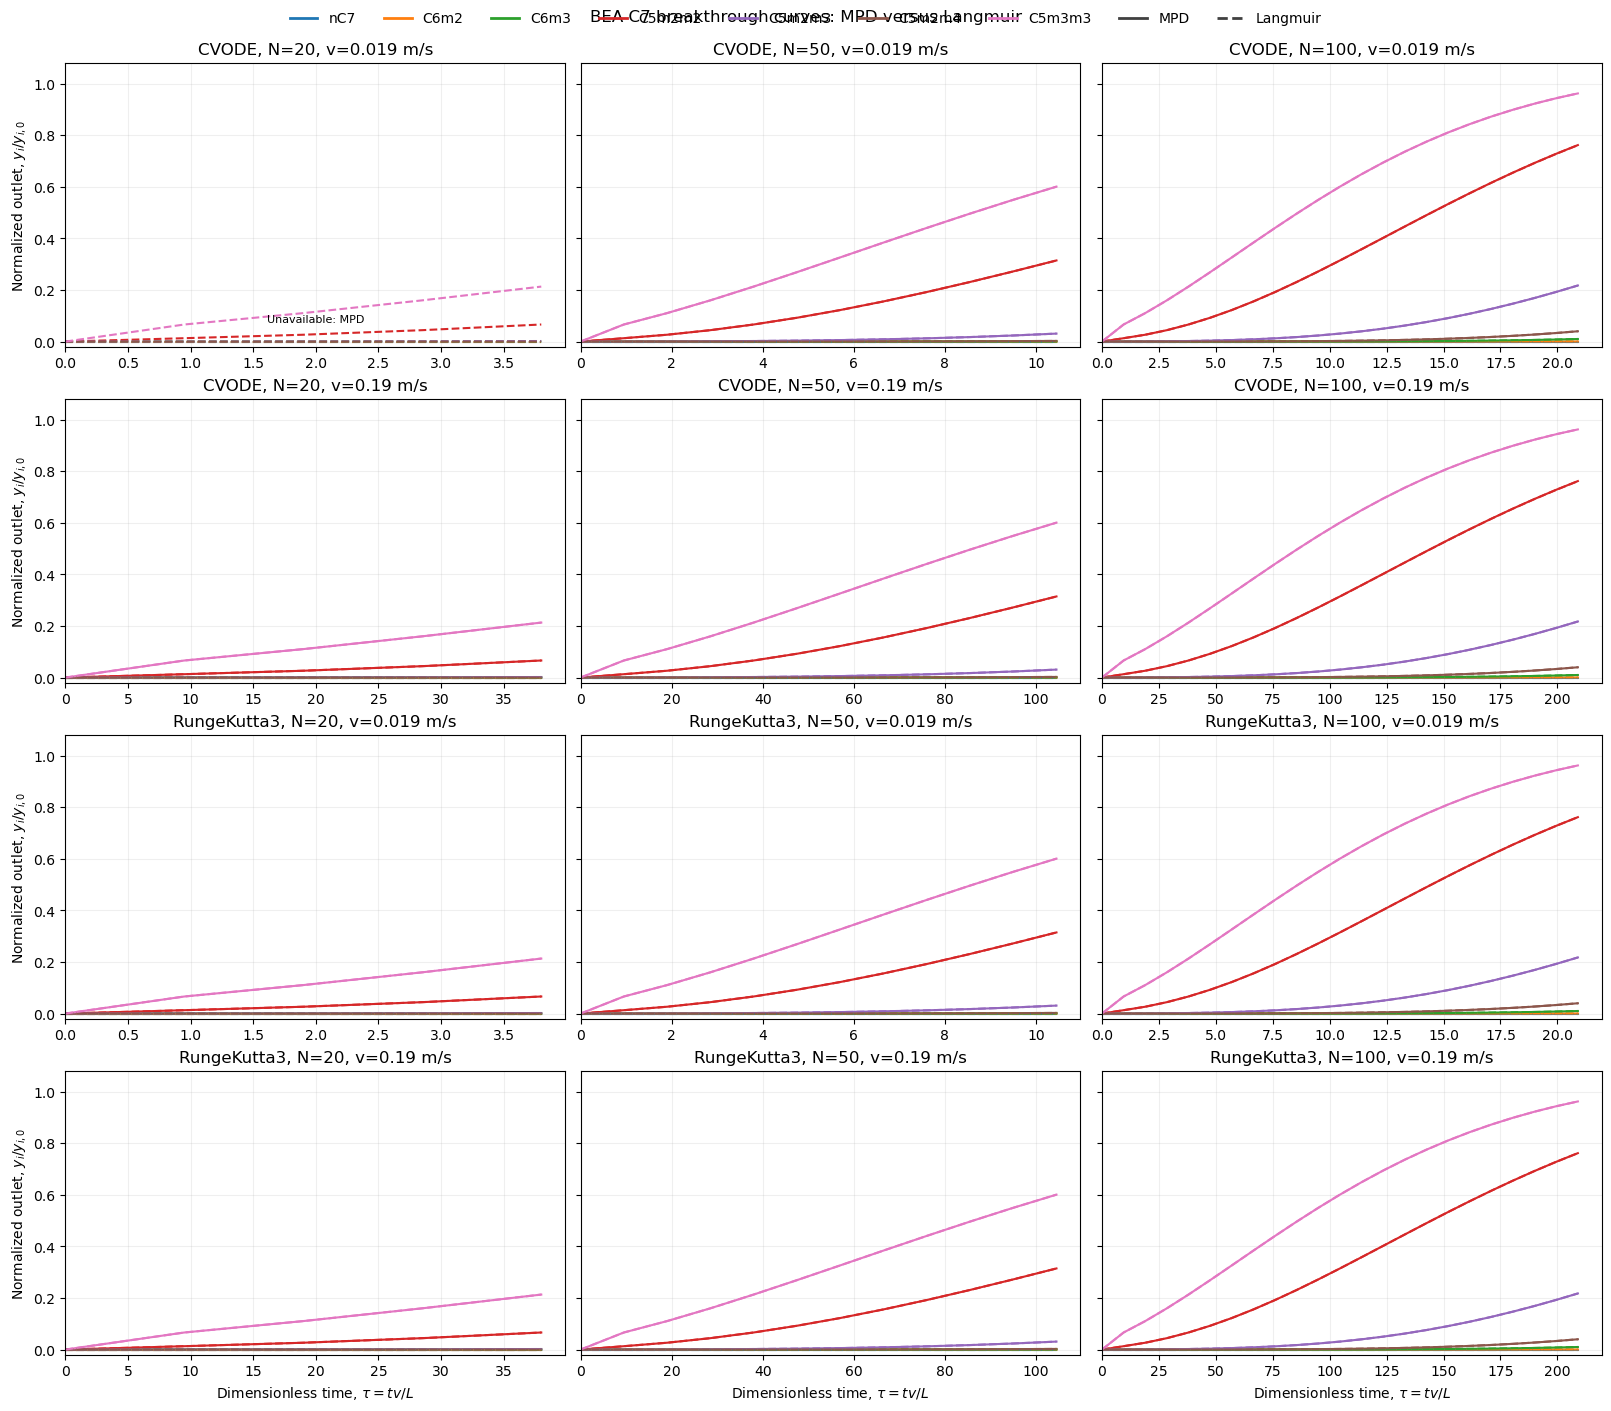

In [3]:
def first_case_directory(model: str, integrator: str, grid_points: int, velocity: float) -> Path:
    matching = [
        (repetition, directory)
        for (case_model, case_integrator, case_grid, case_velocity, repetition), directory in run_lookup.items()
        if case_model == model
        and case_integrator == integrator
        and case_grid == grid_points
        and np.isclose(case_velocity, velocity)
    ]
    if not matching:
        raise FileNotFoundError(f'No directory for {model}, {integrator}, N={grid_points}, v={velocity:g}')
    return min(matching, key=lambda item: item[0])[1]


def outlet_curve(directory: Path, component: str) -> dict[str, np.ndarray]:
    simulation_path = directory / 'simulation.json'
    data_path = directory / f'component_{COMPONENT_INDEX[component]}_{component}.data'
    if not simulation_path.is_file() or not data_path.is_file():
        raise FileNotFoundError(data_path)

    with simulation_path.open(encoding='utf-8') as stream:
        simulation = json.load(stream)
    column_length = float(simulation['ColumnLength'])
    feed_fraction = next(
        float(entry['GasPhaseMolFraction']) for entry in simulation['Components'] if entry['Name'] == component
    )

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        table = np.loadtxt(data_path, comments='#')
    if table.size == 0:
        raise ValueError(f'No numeric output in {data_path}')
    table = np.atleast_2d(table)
    if table.shape[1] < 6:
        raise ValueError(f'Unexpected output format in {data_path}')

    # Filtering by z=L rejects an incomplete block while a simulation is still writing.
    outlet = table[np.isclose(table[:, 2], column_length)]
    if outlet.size == 0:
        raise ValueError(f'No complete outlet profile in {data_path}')
    tau = outlet[:, 0]
    normalized_outlet = outlet[:, 5] / feed_fraction
    _, reverse_indices = np.unique(tau[::-1], return_index=True)
    keep = np.sort(len(tau) - 1 - reverse_indices)
    order = np.argsort(tau[keep])
    return {'tau': tau[keep][order], 'normalized_outlet': normalized_outlet[keep][order]}


component_colors = dict(
    zip(COMPONENTS, plt.get_cmap('tab10').colors[:len(COMPONENTS)], strict=True)
)
row_settings = [(integrator, velocity) for integrator in INTEGRATORS for velocity in VELOCITIES]
fig, axes = plt.subplots(
    len(row_settings), len(GRID_POINTS), figsize=(16, 14), sharey=True, constrained_layout=True
)

for row, (integrator, velocity) in enumerate(row_settings):
    for column, grid_points in enumerate(GRID_POINTS):
        axis = axes[row, column]
        unavailable = []
        plotted = False
        for model, linestyle in (('MPD', '-'), ('Langmuir', '--')):
            try:
                directory = first_case_directory(model, integrator, grid_points, velocity)
                curves = {component: outlet_curve(directory, component) for component in COMPONENTS}
            except (FileNotFoundError, ValueError, KeyError, StopIteration):
                unavailable.append(model)
                continue
            for component, curve in curves.items():
                axis.plot(
                    curve['tau'],
                    curve['normalized_outlet'],
                    color=component_colors[component],
                    linestyle=linestyle,
                    linewidth=1.5,
                )
                plotted = True

        axis.set_title(f'{integrator}, N={grid_points}, v={velocity:g} m/s')
        axis.set_xlim(left=0.0)
        axis.set_ylim(-0.02, 1.08)
        axis.grid(alpha=0.2)
        if unavailable:
            axis.text(
                0.5, 0.08, f"Unavailable: {', '.join(unavailable)}",
                transform=axis.transAxes, ha='center', va='bottom', fontsize=8,
            )
        if not plotted:
            axis.text(0.5, 0.5, 'No complete results', transform=axis.transAxes, ha='center', va='center')
        if row == len(row_settings) - 1:
            axis.set_xlabel(r'Dimensionless time, $\tau=tv/L$')
        if column == 0:
            axis.set_ylabel(r'Normalized outlet, $y_i/y_{i,0}$')

component_handles = [
    Line2D([0], [0], color=component_colors[name], linewidth=2, label=name) for name in COMPONENTS
]
model_handles = [
    Line2D([0], [0], color='0.25', linewidth=2, linestyle='-', label='MPD'),
    Line2D([0], [0], color='0.25', linewidth=2, linestyle='--', label='Langmuir'),
]
fig.legend(
    handles=component_handles + model_handles, loc='outside upper center', ncol=9, frameon=False
)
fig.suptitle('BEA C7 breakthrough curves: MPD versus Langmuir')
plt.show()

## Runtime benchmark

The grouped bars use the `Total time` reported by Ruptura. When multiple repetitions are present, the bar height is their median. A logarithmic time axis keeps both the analytical Langmuir and MPD timings readable on the same chart.

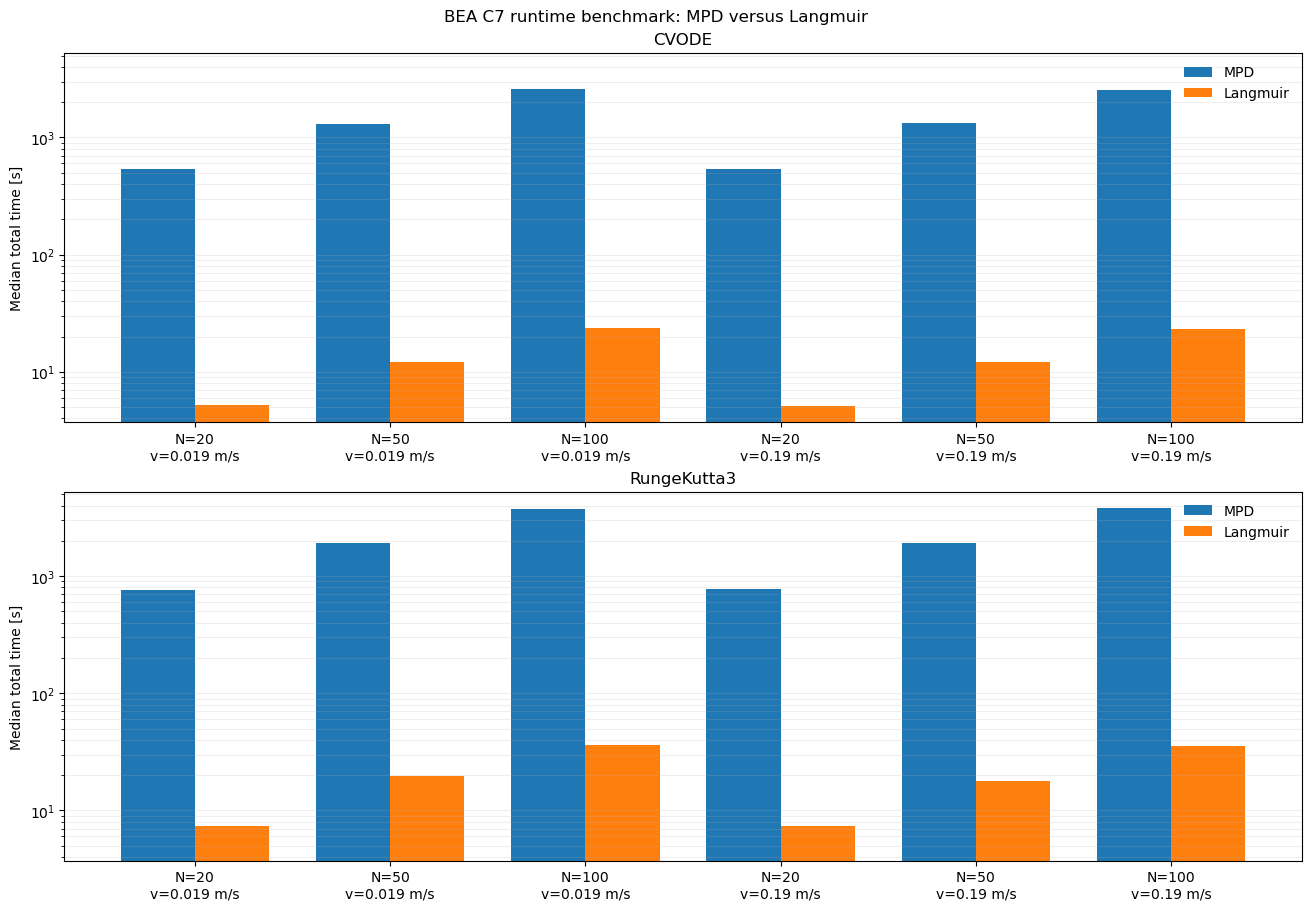


Median Ruptura total times
CVODE       v=0.019 m/s N= 20 Langmuir: 5.212 s (n=1)
CVODE       v=0.019 m/s N= 20 MPD     : 537.350 s (n=1)
CVODE       v=0.019 m/s N= 50 Langmuir: 12.057 s (n=1)
CVODE       v=0.019 m/s N= 50 MPD     : 1312.793 s (n=1)
CVODE       v=0.019 m/s N=100 Langmuir: 23.835 s (n=1)
CVODE       v=0.019 m/s N=100 MPD     : 2585.844 s (n=1)
CVODE       v=0.19 m/s N= 20 Langmuir: 5.143 s (n=1)
CVODE       v=0.19 m/s N= 20 MPD     : 540.961 s (n=1)
CVODE       v=0.19 m/s N= 50 Langmuir: 12.131 s (n=1)
CVODE       v=0.19 m/s N= 50 MPD     : 1314.856 s (n=1)
CVODE       v=0.19 m/s N=100 Langmuir: 23.180 s (n=1)
CVODE       v=0.19 m/s N=100 MPD     : 2520.776 s (n=1)
RungeKutta3 v=0.019 m/s N= 20 Langmuir: 7.335 s (n=1)
RungeKutta3 v=0.019 m/s N= 20 MPD     : 767.898 s (n=1)
RungeKutta3 v=0.019 m/s N= 50 Langmuir: 19.747 s (n=1)
RungeKutta3 v=0.019 m/s N= 50 MPD     : 1923.326 s (n=1)
RungeKutta3 v=0.019 m/s N=100 Langmuir: 36.203 s (n=1)
RungeKutta3 v=0.019 m/s N=100 MPD

In [4]:
timing_groups = {}
for row in runs:
    if np.isfinite(row['total_time_s']):
        key = (row['model'], row['integrator'], row['grid_points'], row['velocity_m_s'])
        timing_groups.setdefault(key, []).append(row['total_time_s'])
timing = [
    {
        'model': key[0], 'integrator': key[1], 'grid_points': key[2], 'velocity_m_s': key[3],
        'median_time_s': float(np.median(values)), 'repetitions': len(values),
    }
    for key, values in timing_groups.items()
]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharey=True, constrained_layout=True)
bar_width = 0.38
model_colors = {'MPD': plt.get_cmap('tab10')(0), 'Langmuir': plt.get_cmap('tab10')(1)}
setting_order = [(grid_points, velocity) for velocity in VELOCITIES for grid_points in GRID_POINTS]
x = np.arange(len(setting_order), dtype=float)

for axis, integrator in zip(axes, INTEGRATORS, strict=True):
    for model, offset in (('MPD', -bar_width / 2), ('Langmuir', bar_width / 2)):
        values = []
        for grid_points, velocity in setting_order:
            selected = next((
                row for row in timing
                if row['model'] == model
                and row['integrator'] == integrator
                and row['grid_points'] == grid_points
                and np.isclose(row['velocity_m_s'], velocity)
            ), None)
            values.append(selected['median_time_s'] if selected else np.nan)
        axis.bar(
            x + offset, values, width=bar_width, color=model_colors[model], label=model
        )

    axis.set_yscale('log')
    axis.set_ylabel('Median total time [s]')
    axis.set_title(integrator)
    axis.set_xticks(
        x, [f'N={grid_points}\nv={velocity:g} m/s' for grid_points, velocity in setting_order]
    )
    axis.grid(axis='y', alpha=0.2, which='both')
    axis.legend(frameon=False)

fig.suptitle('BEA C7 runtime benchmark: MPD versus Langmuir')
plt.show()

print('\nMedian Ruptura total times')
for row in sorted(timing, key=lambda item: (item['integrator'], item['velocity_m_s'], item['grid_points'], item['model'])):
    print(
        f"{row['integrator']:11s} v={row['velocity_m_s']:g} m/s N={row['grid_points']:3d} "
        f"{row['model']:8s}: {row['median_time_s']:.3f} s (n={row['repetitions']})"
    )